#### The Time-Independent Schrodinger Equation (TISE) is given as:
\begin{equation}
    -\frac{\hbar^2}{2m} \frac{d^2 \psi(x)}{dx^2} + V(x) \psi(x) = E \psi(x)
\end{equation}

#### The 1D Potential Barrier is defined as:
\begin{equation}
V(x) = 
\begin{cases}
0, & x \le 0 \\
V_0, & 0 < x < a \\
0, & x > a
\end{cases}
\end{equation}

#### The wavefunctions for tunneling are:
\begin{equation}
    \psi(x) = 
    \begin{cases} 
        A e^{ik_{1}x} + B e^{-ik_{1}x}, & \text{for } x \le 0, \\
        C e^{k_{2}x} + D e^{-k_{2}x}, & \text{for } 0 < x < a, \\
        F e^{ik_{1}x}, & \text{for } x > a,
    \end{cases}
\end{equation}

In [1]:
# Importing necessary packages

import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interactive
import warnings

warnings.filterwarnings("ignore")

#### 1. DEFINING THE CONSTANTS

In [2]:
a = 1
hbar = 1
A = 1
m = 1

E = 0.75
V0 = 1.5
k1 = np.sqrt((2*m*E)/(hbar**2))
k2 = np.sqrt((2*m*(V0-E))/(hbar**2))

#### 2. DEFINING AND MAKING THE POTENTIAL BARRIER

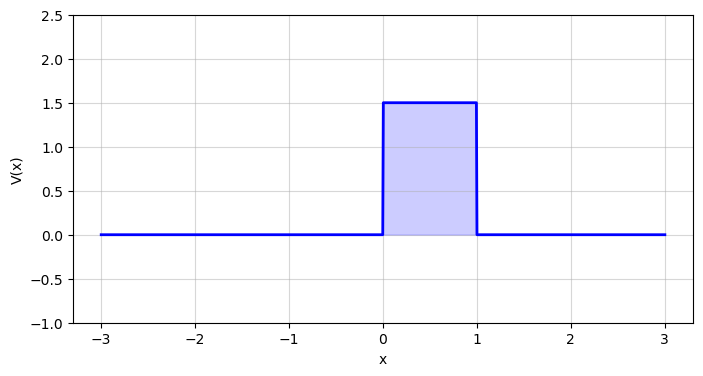

In [3]:
x = np.linspace(-3,3,1000)

V = np.zeros_like(x)
V[(x>0)&(x<a)] = V0

plt.figure(figsize=(8,4))

plt.plot(x,V,color='blue',lw=2)

plt.xlabel("x")
plt.ylabel("V(x)")
plt.grid(alpha=0.5)
plt.ylim(-1,V0+1)
plt.fill_between(x,V,alpha=0.2,color='blue')


plt.show()

#### The continuity conditions at $x = 0$ and at $x = a$ yield:
$$
A+B = C+D
$$
$$
ik_{1}(A-B) = k_{2}(C-D)
$$
$$
Ce^{k_{2}a} + De^{-k_{2}a} = Fe^{ik_{1}a}
$$
$$
k_{2}\left(Ce^{k_{2}a}-De^{-k_{2}a}\right) = ik_{1}Fe^{ik_{1}a}
$$
We solve these equations to get the various coefficients

#### 3. CALCULATING THE COEFFICIENTS (C, D, B/A, F/A and then R & T)

In [4]:
B_A = (-1j*(k1**2 + k2**2)/(k1*k2))*np.sinh(k2*a)*((2*np.cosh(k2*a)+ 1j*((k2**2 - k1**2)/(k1*k2))*np.sinh(k2*a))**(-1))
F_A = 2*np.exp(-1j*k1*a)*((2*np.cosh(k2*a)+1j*((k2**2 - k1**2)/(k1*k2))*np.sinh(k2*a))**(-1))

C = ((F_A*A)/2)*(1+1j*(k1/k2))*np.exp((1j*k1-k2)*a)
D = ((F_A*A)/2)*(1-1j*(k1/k2))*np.exp((1j*k1+k2)*a)

display(C,D,B_A,F_A)

np.complex128(0.07947587131576679+0.0794758713157668j)

np.complex128(0.9205241286842332-0.9205241286842331j)

np.complex128(-0.8410482573684663j)

np.complex128(0.1834860862029146-0.5088916239705684j)

In [5]:
R = np.abs(B_A**2)
T = np.abs(F_A**2)

print("R =",R)
print("T =",T)

R = 0.707362171222534
T = 0.29263782877746575


#### 4. *CHECKING THAT $R+T\approx 1$ ...* 

In [6]:
print("R + T =",(R+T))

R + T = 0.9999999999999998


#### 5. CONSTRUCTING AND PLOTTING THE WAVEFUNCTIONS

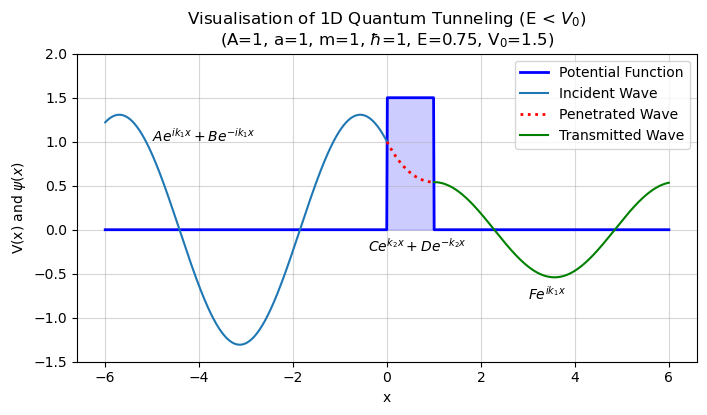

In [7]:
x = np.linspace(-6,6,1000)
x1 = np.linspace(-6,0,1000,endpoint=True)
x2 = np.linspace(0,1,1000,endpoint=True)
x3 = np.linspace(1,6,1000,endpoint=True)

psi1 = A*np.exp(1j*k1*x1) + (B_A*A)*np.exp(-1j*k1*x1)
psi2 = C*np.exp(k2*x2) + D*np.exp(-k2*x2)
psi3 = (F_A*A)*np.exp(1j*k1*x3)

V = np.zeros_like(x)
V[(x>0)&(x<a)] = V0

plt.figure(figsize=(8,4))

plt.plot(x,V,color='blue',lw=2,label="Potential Function")

plt.plot(x1,np.real(psi1),label='Incident Wave')
plt.plot(x2,np.real(psi2),color='red',linestyle='dotted',lw=2,label="Penetrated Wave")
plt.plot(x3,np.real(psi3),color='green',label="Transmitted Wave")
plt.ylim(-1.5,2)
plt.xlabel("x")
plt.ylabel("V(x) and $\\psi(x)$")
plt.grid(alpha=0.5)
plt.title("Visualisation of 1D Quantum Tunneling (E < $V_{0}$)\n(A=1, a=1, m=1, $\\hbar$=1, E=0.75, V$_{0}$=1.5)")
plt.fill_between(x,V,alpha=0.2,color='blue')
plt.legend()
plt.text(-5,1,"$A e^{ik_{1}x} + B e^{-ik_{1}x}$")
plt.text(3,-0.8,"$F e^{ik_{1}x}$")
plt.text(-0.4,-0.25,"$C e^{k_{2}x} + D e^{-k_{2}x}$")

plt.show()

***

CALCULATING $T$ WITH ANALYTIC FORMULA:
$$
T = \left[1+\frac{1}{4}\frac{V_{0}^{2}}{E(V_{0}-E)}\sinh^{2}\left(\frac{a}{\hbar}\sqrt{2m(V_{0}-E)}\right)\right]^{-1}
$$

In [8]:
Tf = 1/(1+((0.25*((V0**2)/(E*(V0-E))))*(np.sinh((a/hbar)*np.sqrt(2*m*(V0-E))))**2))
print("Transmission coefficient using actual formula =",Tf)
error = (abs(Tf-T)/T)*100
print(f"Percentage error according to theoretical value = {error} %")

Transmission coefficient using actual formula = 0.2926378287774659
Percentage error according to theoretical value = 5.69076986353711e-14 %


When $E << V_{0}$, we can approximate $T$ using the following formula:
$
T = \frac{16E}{V_{0}}\left(1-\frac{E}{V_{0}}\right)e^{-(2a/\hbar)\sqrt{2m(V_{0}-E)}}
$

***

##### VARIATION OF REFLECTION AND TRANSMISSION COEFFICIENTS

For $E>V_{0}$, $T$ is given as:
$$
T = \left[1+\frac{1}{4\epsilon(\epsilon-1)}\sin^{2}\left(\lambda\sqrt{\epsilon-1}\right)\right]^{-1}
$$
For $E<V_{0}$, $T$ is given as:
$$
T = \left[1+\frac{1}{4\epsilon(1-\epsilon)}\sinh^{2}\left(\lambda\sqrt{1-\epsilon}\right)\right]^{-1}
$$
Here, $\lambda = a\sqrt{2mV_{0}/\hbar^{2}}$ and $\epsilon = E/V_{0}$. $R$ can easily be caclulated using: $R = 1 - T$

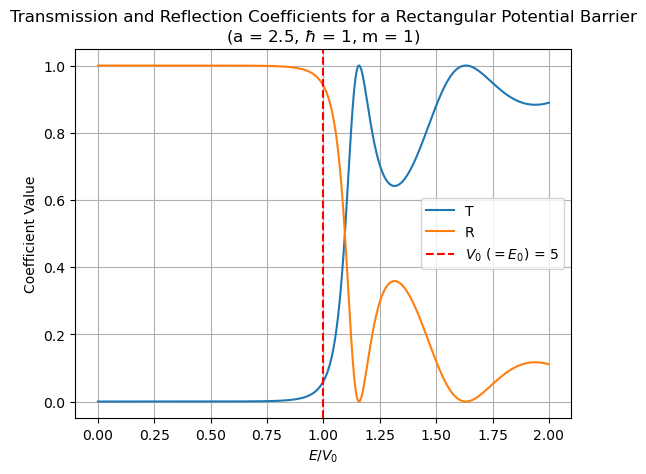

In [9]:
# Defining constants (scaled to 1)
hbar = 1
m = 1
V0 = 5 
a = 2.5
L = a*np.sqrt((2*m*V0)/(hbar**2))

E = np.linspace(0.001,10.0,1000)
epsilon = E/V0

T = np.zeros_like(E)
R = np.zeros_like(E)

# Calculating coefficients for each E/V0
for i,e in enumerate(epsilon):
    if(e<1):
        T[i] = 1/(1+((1/(4*e*(1-e)))*((np.sinh(L*np.sqrt(1-e)))**2)))
    else:
        T[i] = 1/(1+((1/(4*e*(e-1)))*((np.sin(L*np.sqrt(e-1)))**2)))
    R[i] = 1-T[i]

# Plotting the coefficients
plt.plot(epsilon,T,label='T')
plt.plot(epsilon,R,label='R')
plt.axvline(x=epsilon[499],color='red',linestyle='--',label=fr'$V_{0}$ $\left(=E_{0}\right)$ = {V0}')

plt.xlabel(r'$E/V_{0}$')
plt.ylabel('Coefficient Value')
plt.title('Transmission and Reflection Coefficients for a Rectangular Potential Barrier'+"\n"+f"(a = {a}, $\\hbar$ = 1, m = 1)")
plt.grid(True)
plt.legend()

plt.show()

[Note: We don't focus much on the $E>V_{0}$ case as it is of less physical importance]

***